# Task 2: Hashtag Co-occurrence & Community Detection

1. Build a hashtag co-occurrence network (two hashtags are linked if they appear in the same tweet).
2. Find communities with **Louvain** (topology only).
3. Learn node embeddings with a **GNN** (Graph Autoencoder with GCN layers), then cluster them with **KMeans**.
4. Compare the two clusterings.

In [1]:
%pip install torch torchvision --index-url https://download.pytorch.org/whl/cpu
%pip install torch_geometric scikit-learn

Looking in indexes: https://download.pytorch.org/whl/cpu
  Using cached sympy-1.14.0-py3-none-any.whl.metadata (12 kB)
  Using cached mpmath-1.3.0-py3-none-any.whl.metadata (8.6 kB)
   ---------------------------------------- 0.0/128.6 MB ? eta -:--:--
   ---------------------------------------- 0.3/128.6 MB ? eta -:--:--
   ---------------------------------------- 0.5/128.6 MB 1.9 MB/s eta 0:01:08
   ---------------------------------------- 1.0/128.6 MB 2.4 MB/s eta 0:00:53
    --------------------------------------- 2.4/128.6 MB 3.7 MB/s eta 0:00:35
   - -------------------------------------- 3.4/128.6 MB 3.9 MB/s eta 0:00:33
   - -------------------------------------- 4.7/128.6 MB 4.4 MB/s eta 0:00:28
   - -------------------------------------- 5.8/128.6 MB 4.4 MB/s eta 0:00:28
   -- ------------------------------------- 7.1/128.6 MB 4.8 MB/s eta 0:00:26
   -- ------------------------------------- 7.9/128.6 MB 4.7 MB/s eta 0:00:26
   -- ------------------------------------- 8.7/128.


[notice] A new release of pip is available: 26.1.1 -> 26.3
[notice] To update, run: C:\Users\taesp\AppData\Local\Python\pythoncore-3.14-64\python.exe -m pip install --upgrade pip


   ---------------------------------------- 0.0/1.3 MB ? eta -:--:--
   ----------------------- ---------------- 0.8/1.3 MB 4.2 MB/s eta 0:00:01
   ---------------------------------------- 1.3/1.3 MB 2.9 MB/s  0:00:00

   ---- -----------------------------------  1/10 [tqdm]
   ---- -----------------------------------  1/10 [tqdm]
   ---- -----------------------------------  1/10 [tqdm]
   -------- -------------------------------  2/10 [propcache]
   ------------ ---------------------------  3/10 [multidict]
   -------------------- -------------------  5/10 [aiohappyeyeballs]
   ------------------------ ---------------  6/10 [yarl]
   ---------------------------- -----------  7/10 [aiosignal]
   -------------------------------- -------  8/10 [aiohttp]
   -------------------------------- -------  8/10 [aiohttp]
   -------------------------------- -------  8/10 [aiohttp]
   -------------------------------- -------  8/10 [aiohttp]
   -------------------------------- -------  8/10 [aiohttp


[notice] A new release of pip is available: 26.1.1 -> 26.3
[notice] To update, run: C:\Users\taesp\AppData\Local\Python\pythoncore-3.14-64\python.exe -m pip install --upgrade pip


In [ ]:
import os
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx
from collections import Counter
from itertools import combinations

plt.style.use('default')
plt.rcParams['figure.facecolor'] = 'white'
plt.rcParams['axes.facecolor'] = 'white'
plt.rcParams['savefig.facecolor'] = 'white'
plt.rcParams['savefig.transparent'] = False

## Extract hashtags

- The pattern includes the Devanagari range (`\u0900-\u097F`) in lowercase.
- A hashtag repeated in one tweet is counted once.

In [3]:
hashtag_pattern = re.compile(r'#([\w\u0900-\u097F]+)')

def extract_hashtags(text):
    if not isinstance(text, str):
        return []
    return sorted(set(h.lower() for h in hashtag_pattern.findall(text)))

In [4]:
print(extract_hashtags("RT @TFC_mass: @ActorKartikeya Lots Of Love &amp; Support From #Ajithkumar Fans !!"))
print(extract_hashtags("#IPL2022 #CSK #csk #Dhoni what a match"))
print(extract_hashtags("no hashtags here"))

['ajithkumar']
['csk', 'dhoni', 'ipl2022']
[]


## Count hashtags and pairs from the full dataset

For every tweet with hashtags we count:
- how many tweets use each hashtag (`tag_count`)
- how many of those are retweets (`rt_count`) and the sum of years (for the mean year), used later as **node attributes**
- every **pair** of hashtags in the same tweet (`pair_count`), which becomes an edge

Tweets with more than 10 hashtags are skipped since they are most likely spam, and they create a huge number of pairs.

Results are saved to `hashtag_nodes.csv` and `hashtag_edges.csv`.

In [5]:
NODES_FILE = 'hashtag_nodes.csv'
EDGES_FILE = 'hashtag_edges.csv'

if os.path.exists(NODES_FILE) and os.path.exists(EDGES_FILE):
    tag_info = pd.read_csv(NODES_FILE, keep_default_na=False).set_index('hashtag')
    tag_edges = pd.read_csv(EDGES_FILE, keep_default_na=False)
    print('Loaded from cache')
else:
    tag_count = Counter()
    rt_count = Counter()
    year_sum = Counter()
    pair_count = Counter()
    total_tweets = 0
    tweets_with_tags = 0

    reader = pd.read_json('tweets.jsonl', lines=True, chunksize=500_000, dtype=False)
    for chunk in reader:
        chunk = chunk[['tweet_text', 'datetime']].dropna()
        total_tweets += len(chunk)
        chunk = chunk[chunk['tweet_text'].str.contains('#')]

        for text, dt in zip(chunk['tweet_text'], chunk['datetime']):
            tags = extract_hashtags(text)
            if not tags:
                continue
            tweets_with_tags += 1
            year = int(str(dt)[:4])
            is_rt = text.startswith('RT @')

            for t in tags:
                tag_count[t] += 1
                year_sum[t] += year
                if is_rt:
                    rt_count[t] += 1

            if 2 <= len(tags) <= 10:
                for a, b in combinations(tags, 2):
                    pair_count[(a, b)] += 1

        print('tweets read so far:', total_tweets)

    tag_info = pd.DataFrame({
        'count': pd.Series(tag_count),
        'rt_share': pd.Series(rt_count) / pd.Series(tag_count),
        'mean_year': pd.Series(year_sum) / pd.Series(tag_count),
    })
    tag_info['rt_share'] = tag_info['rt_share'].fillna(0)
    tag_info.index.name = 'hashtag'
    tag_info.to_csv(NODES_FILE)

    tag_edges = pd.DataFrame(
        [(a, b, w) for (a, b), w in pair_count.items()],
        columns=['source', 'target', 'weight'],
    )
    tag_edges.to_csv(EDGES_FILE, index=False)

    print('Total tweets:', total_tweets, '| tweets with hashtags:', tweets_with_tags)
    del tag_count, rt_count, year_sum, pair_count   # free memory

print('Unique hashtags:', len(tag_info))
print('Unique hashtag pairs:', len(tag_edges))

tweets read so far: 500000
tweets read so far: 1000000
tweets read so far: 1500000
tweets read so far: 2000000
tweets read so far: 2500000
tweets read so far: 3000000
tweets read so far: 3500000
tweets read so far: 4000000
tweets read so far: 4500000
tweets read so far: 5000000
tweets read so far: 5500000
tweets read so far: 6000000
tweets read so far: 6500000
tweets read so far: 7000000
tweets read so far: 7500000
tweets read so far: 7753653
Total tweets: 7753653 | tweets with hashtags: 2611183
Unique hashtags: 463764
Unique hashtag pairs: 2056937


In [6]:
tag_info.sort_values('count', ascending=False).head(20)

,count,rt_share,mean_year
hashtag,,,
watch,45932,0.968236,2021.487329
covid19,35679,0.671600,2021.048880
valimai,34588,0.811091,2021.101047
ajithkumar,28760,0.706850,2021.402990
bharatjodoyatra,22871,0.894233,2022.000000
india,20755,0.311588,2021.396242
beast,19240,0.783420,2021.450260
prabhas,17282,0.793137,2021.281970
master,17031,0.779989,2020.925900


In [7]:
tag_edges.sort_values('weight', ascending=False).head(20)

,source,target,weight
105,ajithkumar,valimai,15246
369,ajithkumar,thunivu,7983
364,beast,master,6352
624,property,residential,5916
613,forsale,property,5713
1105,pratikistheboss,pratiksehajpal,5166
615,forsale,residential,4818
940,karanistheboss,karankundrra,4461
684,modi_job_do,modi_rojgar_do,4169
1208,nogutsnoglory,thunivu,4095


## Build the co-occurrence graph

The raw graph has a lot of hashtags used only once or twice. They are noise and will probably make the GNN slow, so we keep:
- hashtags used in at least `MIN_TAG_COUNT` tweets
- pairs that **co-occur** at least `MIN_EDGE_WEIGHT` times
- only the **largest connected component** (communities need a connected graph)

In [8]:
MIN_TAG_COUNT = 50
MIN_EDGE_WEIGHT = 5

keep_tags = set(tag_info[tag_info['count'] >= MIN_TAG_COUNT].index)
e = tag_edges[(tag_edges['weight'] >= MIN_EDGE_WEIGHT)
              & tag_edges['source'].isin(keep_tags)
              & tag_edges['target'].isin(keep_tags)]

G_full = nx.Graph()
G_full.add_weighted_edges_from(e[['source', 'target', 'weight']].itertuples(index=False))
print('After filtering:', G_full.number_of_nodes(), 'nodes,', G_full.number_of_edges(), 'edges')

largest_cc = max(nx.connected_components(G_full), key=len)
G = G_full.subgraph(largest_cc).copy()
print('Largest component:', G.number_of_nodes(), 'nodes,', G.number_of_edges(), 'edges')

After filtering: 10678 nodes, 65780 edges
Largest component: 10435 nodes, 65614 edges


In [9]:
print('Density:', nx.density(G))
print('Average degree:', 2 * G.number_of_edges() / G.number_of_nodes())

degrees = pd.Series(dict(G.degree()))
degrees.sort_values(ascending=False).head(15)

Density: 0.0012052668843950231
Average degree: 12.575754671777672


india             1517
covid19            625
bjp                458
delhi              393
farmersprotest     374
mumbai             365
valimai            350
breaking           336
prabhas            327
beast              327
teamindia          325
master             310
cricket            288
shehnaazgill       276
pakistan           266
dtype: int64

## Louvain community detection

Louvain greedily moves nodes between communities to maximize **modularity** (more edges inside communities than random).

In [10]:
louvain_comms = nx.community.louvain_communities(G, weight='weight', seed=42)
louvain_comms = sorted(louvain_comms, key=len, reverse=True)   # biggest first

print('Number of communities:', len(louvain_comms))
print('Modularity:', nx.community.modularity(G, louvain_comms, weight='weight'))
print('Sizes of the 15 biggest:', [len(c) for c in louvain_comms[:15]])

Number of communities: 52
Modularity: 0.8363732754996713
Sizes of the 15 biggest: [2225, 1076, 858, 564, 500, 496, 463, 409, 392, 364, 311, 287, 280, 256, 236]


What is each community about?

In [ ]:
def show_communities(comms, n_comms=12, n_tags=10):
    for i, c in enumerate(comms[:n_comms]):
        top = tag_info.loc[list(c), 'count'].sort_values(ascending=False).head(n_tags)
        print(f'Community {i} ({len(c)} hashtags):', ', '.join(top.index))
        print()

# only n_comms = 12 shown here for reference
show_communities(louvain_comms)

Community 0 (2225 hashtags): watch, covid19, bharatjodoyatra, india, breaking, delhi, covid, bjp, newsalert, maharashtra

Community 1 (1076 hashtags): godmorningmonday, godmorningwednesday, godmorningsaturday, godmorningfriday, mondaymotivation, love, godmorningthursday, twitter, godmorningtuesday, trending

Community 2 (858 hashtags): prabhas, sarkaruvaaripaata, pushpa, kgfchapter2, rrrmovie, radheshyam, bheemlanayak, rrr, ramcharan, maheshbabu

Community 3 (564 hashtags): teamindia, ipl2021, whistlepodu, indvseng, t20worldcup, indveng, viratkohli, csk, yellove, ipl2022

Community 4 (500 hashtags): sushantday, justiceforsushantsinghrajput, salmankhan, shahrukhkhan, akshaykumar, sushantsinghrajput, bollywood, boycottbollywood, brahmastra, pathaan

Community 5 (496 hashtags): mannkibaat, farmersprotest, farmlaws, republicday, farmers, railway_groupd_examdate, indiaagainstpropaganda, indiatogether, justiceforrinkusharma, farmersprotests

Community 6 (463 hashtags): beast, master, varisu,

Which community is `#ajithkumar` in?

In [12]:
node_list = list(G.nodes())
louvain_label = {n: i for i, c in enumerate(louvain_comms) for n in c}

if 'ajithkumar' in louvain_label:
    c = louvain_label['ajithkumar']
    print('ajithkumar is in community', c)
    top = tag_info.loc[list(louvain_comms[c]), 'count'].sort_values(ascending=False).head(25)
    print(', '.join(top.index))
else:
    print('ajithkumar was filtered out, try lowering MIN_TAG_COUNT / MIN_EDGE_WEIGHT')

ajithkumar is in community 18
valimai, ajithkumar, thunivu, valimaitrailer, nogutsnoglory, thala, ak61, thalaajith, hvinoth, chillachilla, ajith, ak, decadeofkwpridemankatha, valimaimotionposter, valimaiglimpse, valimaipongal, ak61firstlook, valimaimakingvideo, valimaiupdate, chillachillafromdec9, naangaveramaari, a, valimaifirstlook, whistletheme, thunivupongal


## Node features

The GNN needs a feature vector for each hashtag. We keep it simple:

| feature | meaning |
|---|---|
| `log_count` | how popular the hashtag is (log, because counts are very skewed) |
| `rt_share` | share of its tweets that are retweets |
| `mean_year` | when it was mostly used (2014 to 2022) |
| `log_degree` | how many other hashtags it appears with |
| `log_strength` | total co-occurrence weight |
| `clustering` | how connected its neighbours are to each other |

All features are standardized (mean 0, std 1).

In [13]:
features = pd.DataFrame(index=node_list)
features['log_count'] = np.log1p(tag_info.loc[node_list, 'count'].values)
features['rt_share'] = tag_info.loc[node_list, 'rt_share'].values
features['mean_year'] = tag_info.loc[node_list, 'mean_year'].values
features['log_degree'] = np.log1p([G.degree(n) for n in node_list])
features['log_strength'] = np.log1p([G.degree(n, weight='weight') for n in node_list])
features['clustering'] = pd.Series(nx.clustering(G)).loc[node_list].values

features = (features - features.mean()) / features.std()
features = features.fillna(0)
features.describe()

,log_count,rt_share,mean_year,log_degree,log_strength,clustering
count,1.043500e+04,1.043500e+04,1.043500e+04,1.043500e+04,1.043500e+04,1.043500e+04
mean,6.972647e-16,-2.178952e-17,-4.782106e-13,4.357905e-17,8.715809e-17,-4.357905e-17
std,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00
min,-1.150774e+00,-1.631936e+00,-3.232155e+00,-1.411839e+00,-1.871972e+00,-1.480051e+00
25%,-7.578042e-01,-8.545900e-01,-7.841645e-01,-6.786554e-01,-6.630670e-01,-8.049469e-01
50%,-2.620522e-01,9.540261e-03,-1.034700e-02,-8.671608e-02,-5.238171e-02,-1.732577e-02
75%,4.971206e-01,7.903010e-01,6.175674e-01,5.680790e-01,6.084383e-01,8.603093e-01
max,5.781248e+00,2.078725e+00,1.544453e+00,5.603229e+00,4.365308e+00,1.445399e+00


## GNN embeddings (Graph Autoencoder)

GCN layer updates each node's vector by averaging it with its neighbours' vectors.
We use **two** layers and hence the embedding mixes information from hashtags up to 2 steps away.

We have no labels, so we train it **unsupervised** as a Graph Autoencoder (**GAE**):
- the **encoder** (2 GCN layers) turns features + graph into a 32-dim embedding `z` per node
- the **decoder** predicts an edge between two nodes if their `z` vectors have a high dot product
- the **loss** rewards predicting real edges and penalises predicting random non-edges

In [ ]:
import torch
from torch_geometric.nn import GCNConv, GAE

torch.manual_seed(42)

# node name -> integer index
idx = {n: i for i, n in enumerate(node_list)}

# build undirected graph edges
src = [idx[a] for a, b in G.edges()]
dst = [idx[b] for a, b in G.edges()]
edge_index = torch.tensor([src + dst, dst + src], dtype=torch.long)

x = torch.tensor(features.values, dtype=torch.float)
print('x:', x.shape, '| edge_index:', edge_index.shape)

C:\Users\taesp\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\torch\jit\_script.py:1485: FutureWarning: `torch.jit.script` is not supported in Python 3.14+ and may break. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


x: torch.Size([10435, 6]) | edge_index: torch.Size([2, 131228])


In [15]:
class Encoder(torch.nn.Module):
    def __init__(self, in_dim, hidden_dim, out_dim):
        super().__init__()
        self.conv1 = GCNConv(in_dim, hidden_dim)
        self.conv2 = GCNConv(hidden_dim, out_dim)

    def forward(self, x, edge_index):
        x = self.conv1(x, edge_index).relu()
        return self.conv2(x, edge_index)

model = GAE(Encoder(x.shape[1], 64, 32))
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

In [16]:
losses = []
for epoch in range(1, 301):
    model.train()
    optimizer.zero_grad()
    z = model.encode(x, edge_index)
    loss = model.recon_loss(z, edge_index)   # real edges vs random negative edges
    loss.backward()
    optimizer.step()
    losses.append(loss.item())
    if epoch % 25 == 0:
        print(f'epoch {epoch}  loss {loss.item():.4f}')

epoch 25  loss 0.9566
epoch 50  loss 0.9283
epoch 75  loss 0.9077
epoch 100  loss 0.8933
epoch 125  loss 0.8824
epoch 150  loss 0.8791
epoch 175  loss 0.8758
epoch 200  loss 0.8700
epoch 225  loss 0.8670
epoch 250  loss 0.8651
epoch 275  loss 0.8643
epoch 300  loss 0.8623


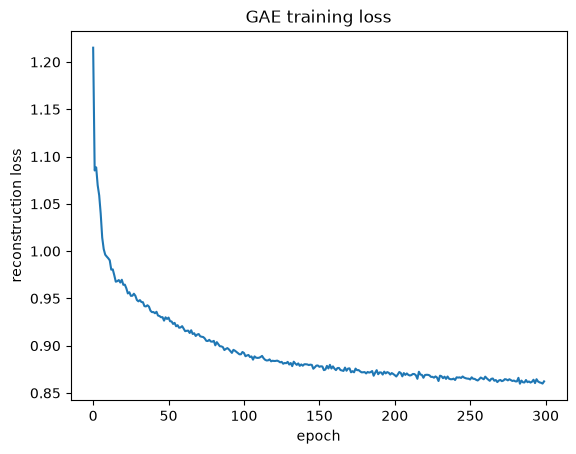

In [17]:
plt.plot(losses)
plt.xlabel('epoch')
plt.ylabel('reconstruction loss')
plt.title('GAE training loss')
plt.show()

In [18]:
model.eval()
with torch.no_grad():
    Z = model.encode(x, edge_index).numpy()
print('Embeddings:', Z.shape)

Embeddings: (10435, 32)


## Cluster the embeddings with KMeans

To compare fairly, we use the **same number of clusters as Louvain** found.
We also check the silhouette score for other values of k, to see what the embeddings prefer.

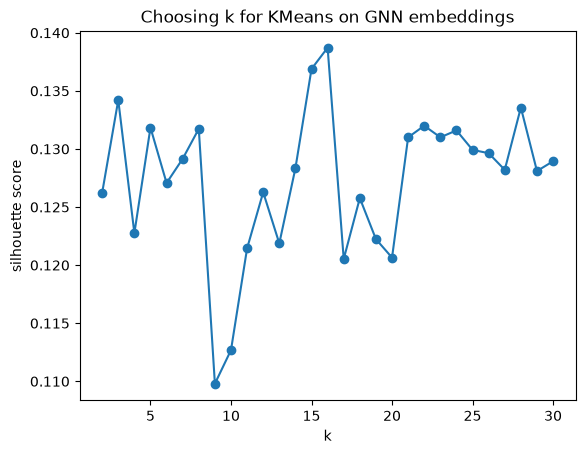

Best k by silhouette: 16


In [19]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

k_values = range(2, 31)
sil = []
for k in k_values:
    labels_k = KMeans(n_clusters=k, n_init=10, random_state=42).fit_predict(Z)
    sil.append(silhouette_score(Z, labels_k))

plt.plot(list(k_values), sil, marker='o')
plt.xlabel('k')
plt.ylabel('silhouette score')
plt.title('Choosing k for KMeans on GNN embeddings')
plt.show()

print('Best k by silhouette:', list(k_values)[int(np.argmax(sil))])

In [20]:
K = len(louvain_comms)
kmeans_labels = KMeans(n_clusters=K, n_init=10, random_state=42).fit_predict(Z)

# turn labels into a list of sets (same format as Louvain), biggest first
kmeans_comms = [set(np.array(node_list)[kmeans_labels == c]) for c in range(K)]
kmeans_comms = sorted([c for c in kmeans_comms if len(c) > 0], key=len, reverse=True)

print('KMeans clusters:', len(kmeans_comms))
print('Sizes of the 15 biggest:', [len(c) for c in kmeans_comms[:15]])

KMeans clusters: 52
Sizes of the 15 biggest: [617, 499, 486, 482, 450, 419, 366, 362, 352, 324, 320, 298, 280, 278, 244]


In [21]:
show_communities(kmeans_comms)

Community 0 (617 hashtags): railway_groupd_examdate, upscextraattempt, bestwayofliving, gandhijayanti, holi, happybirthdaydeepikapadukone, swamivivekananda, teachersday, newprofilepic, kashivishwanathdham

Community 1 (499 hashtags): sushantday, parakramdivas, aatmanirbharbharatkabudget, pulwamaattack, opinion, netajisubhaschandrabose, milkhasingh, armyday, indiasprideviratkohli, sthapnadiwas

Community 2 (486 hashtags): oxygenexpress, parikshapecharcha, आज_भारत_बंद_है, justice4malenurses, characterlesspigntr, poribortonyatra, save_male_nurses, rememberingrajivgandhi, stanswamy, f

Community 3 (482 hashtags): favduoalynjas, 1yearoficonicwinnersid, shonashonaon25thnov, army, lift, myuniverse, kavin, askrubi, happybirthdayshehnaaz, amas

Community 4 (450 hashtags): engineersday, euro2020, apjabdulkalam, msgofaadiramondussehra, bhagatsingh, yuvashaktiwithmodi, happylohri, maritalrape, genderbiasedlaws, iqooraidnights

Community 5 (419 hashtags): worldhealthday, tmcpfoundationday, lunarcru

## Comparison of the two clusterings

| metric | measures | what's better |
|---|---|---|
| **Modularity** | edges inside communities vs random (graph view) | higher |
| **Avg conductance** | share of a community's edges that leave it (graph view) | lower |
| **Silhouette** | how well separated clusters are in embedding space | higher (max 1) |
| **Davies-Bouldin** | average similarity of each cluster to its closest other cluster (embedding view) | lower |
| **NMI / ARI** | how much the two clusterings agree with each other | 1 = identical, 0 = unrelated |

Louvain optimises modularity directly, so it should win the graph metrics.
KMeans optimises distances in embedding space, so it should win silhouette / Davies-Bouldin.

In [22]:
from sklearn.metrics import davies_bouldin_score, normalized_mutual_info_score, adjusted_rand_score

louvain_labels = np.array([louvain_label[n] for n in node_list])

def avg_conductance(comms):
    vals = [nx.conductance(G, c, weight='weight') for c in comms if 0 < len(c) < len(G)]
    return np.mean(vals)

results = pd.DataFrame({
    'Louvain': [
        nx.community.modularity(G, louvain_comms, weight='weight'),
        avg_conductance(louvain_comms),
        silhouette_score(Z, louvain_labels),
        davies_bouldin_score(Z, louvain_labels),
        len(louvain_comms),
    ],
    'GNN + KMeans': [
        nx.community.modularity(G, kmeans_comms, weight='weight'),
        avg_conductance(kmeans_comms),
        silhouette_score(Z, kmeans_labels),
        davies_bouldin_score(Z, kmeans_labels),
        len(kmeans_comms),
    ],
}, index=['modularity', 'avg conductance', 'silhouette (embeddings)', 'davies-bouldin (embeddings)', 'number of clusters'])
results

,Louvain,GNN + KMeans
modularity,0.836373,0.424682
avg conductance,0.080056,0.540567
silhouette (embeddings),-0.067509,0.137360
davies-bouldin (embeddings),2.666579,1.459153
number of clusters,52.000000,52.000000


In [23]:
print('NMI between Louvain and KMeans:', normalized_mutual_info_score(louvain_labels, kmeans_labels))
print('ARI between Louvain and KMeans:', adjusted_rand_score(louvain_labels, kmeans_labels))

NMI between Louvain and KMeans: 0.36992218369004976
ARI between Louvain and KMeans: 0.11203807030327018


In [24]:
results.to_csv('task2_comparison.csv')

## Visualise

### Embeddings in 2D (t-SNE)
t-SNE squashes the 32-dim embeddings down to 2D. Same points, coloured two ways.

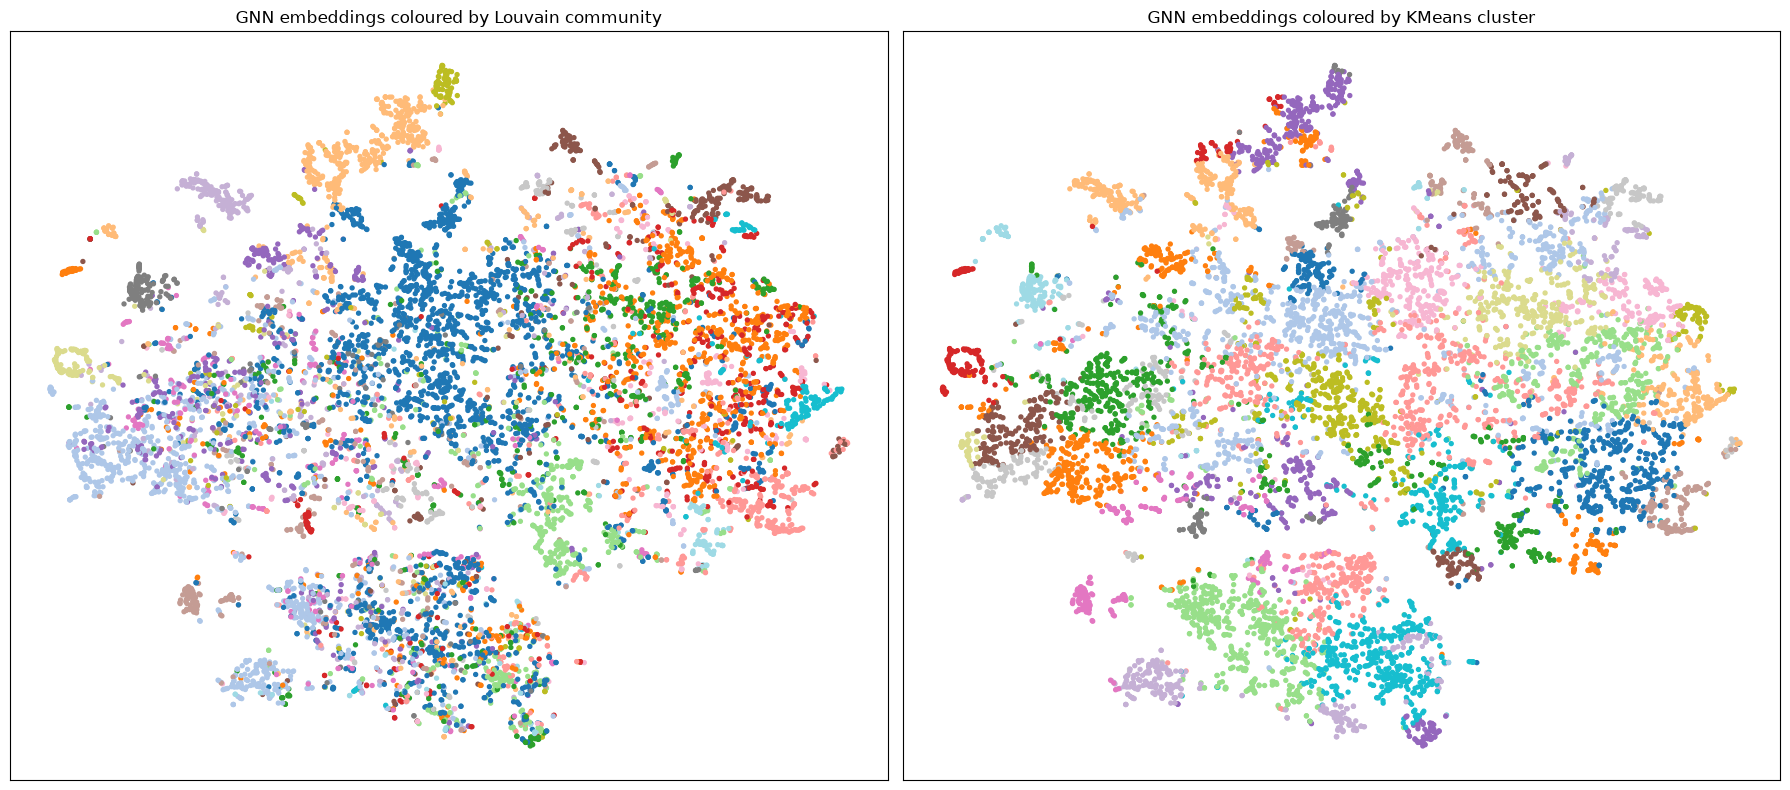

In [25]:
from sklearn.manifold import TSNE

Z_2d = TSNE(n_components=2, random_state=42, init='pca').fit_transform(Z)

fig, axes = plt.subplots(1, 2, figsize=(18, 8))
axes[0].scatter(Z_2d[:, 0], Z_2d[:, 1], c=louvain_labels % 20, cmap='tab20', s=8)
axes[0].set_title('GNN embeddings coloured by Louvain community')
axes[1].scatter(Z_2d[:, 0], Z_2d[:, 1], c=kmeans_labels % 20, cmap='tab20', s=8)
axes[1].set_title('GNN embeddings coloured by KMeans cluster')
for ax in axes:
    ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout()
plt.savefig('tsne_embeddings.svg', bbox_inches='tight')
plt.show()

### Network of the top hashtags, coloured by community
Note: graph is only of the most-used hashtags, otherwise it is unreadable.

In [26]:
def draw_hashtag_network(labels_dict, title, n_top=80, filename=None):
    top_tags = tag_info.loc[node_list, 'count'].sort_values(ascending=False).head(n_top).index
    H = G.subgraph(top_tags)

    counts = np.array([tag_info.loc[n, 'count'] for n in H.nodes()])
    sizes = 150 + 2500 * np.sqrt(counts / counts.max())
    colors = [labels_dict[n] % 20 for n in H.nodes()]

    weights = [H[a][b]['weight'] for a, b in H.edges()]
    max_w = max(weights)
    widths = [0.3 + 2.5 * np.log1p(w) / np.log1p(max_w) for w in weights]

    pos = nx.kamada_kawai_layout(H, weight=None)

    fig, ax = plt.subplots(figsize=(16, 13))
    nx.draw_networkx_edges(H, pos, ax=ax, width=widths, alpha=0.2, edge_color='grey')
    nx.draw_networkx_nodes(H, pos, ax=ax, node_size=sizes, node_color=colors, cmap='tab20',
                           vmin=0, vmax=19, alpha=0.9, edgecolors='black', linewidths=0.5)
    label_pos = {u: (px, py - 0.04) for u, (px, py) in pos.items()}
    nx.draw_networkx_labels(H, label_pos, ax=ax, font_size=8,
                            bbox=dict(facecolor='white', edgecolor='none', alpha=0.7, pad=1))
    ax.set_title(title, fontsize=16)
    ax.axis('off')
    ax.margins(0.08)
    plt.tight_layout()
    if filename:
        plt.savefig(filename, bbox_inches='tight')
    plt.show()

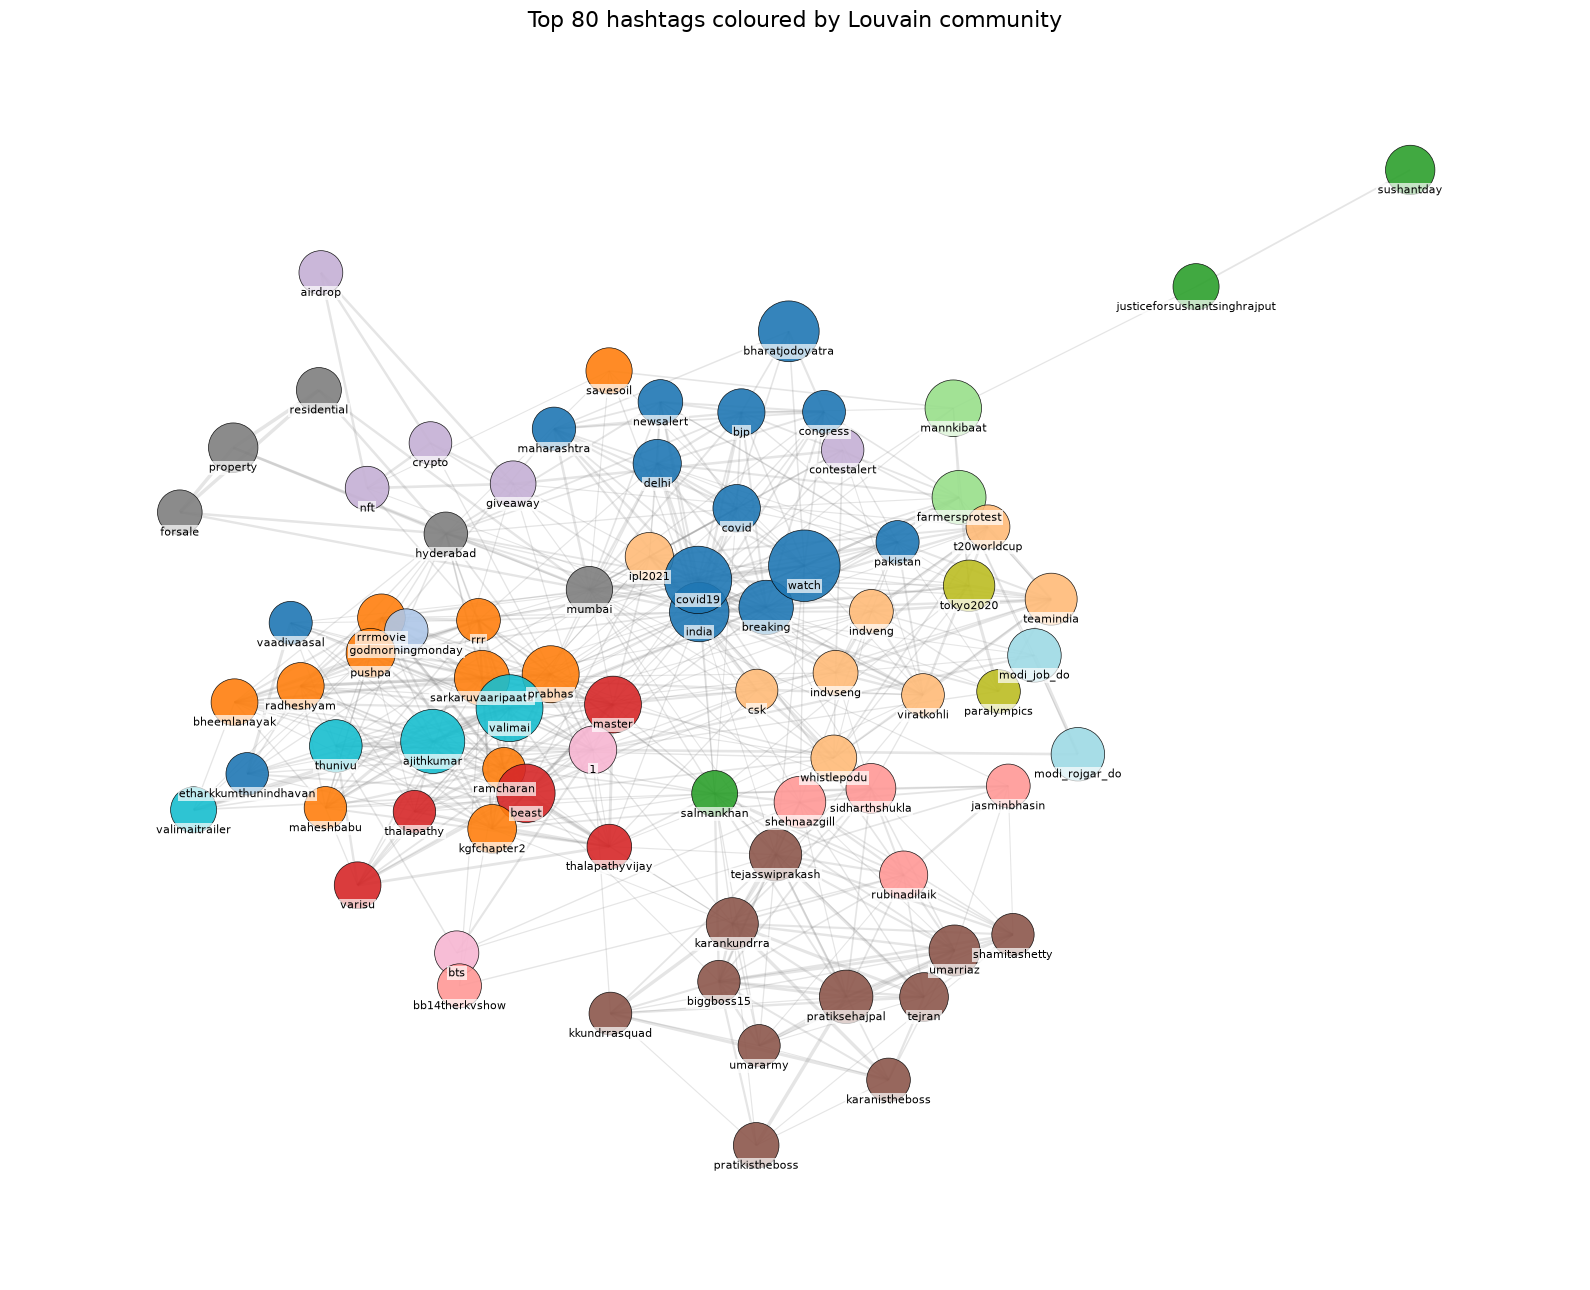

In [27]:
draw_hashtag_network(louvain_label, 'Top 80 hashtags coloured by Louvain community', filename='hashtags_louvain.svg')

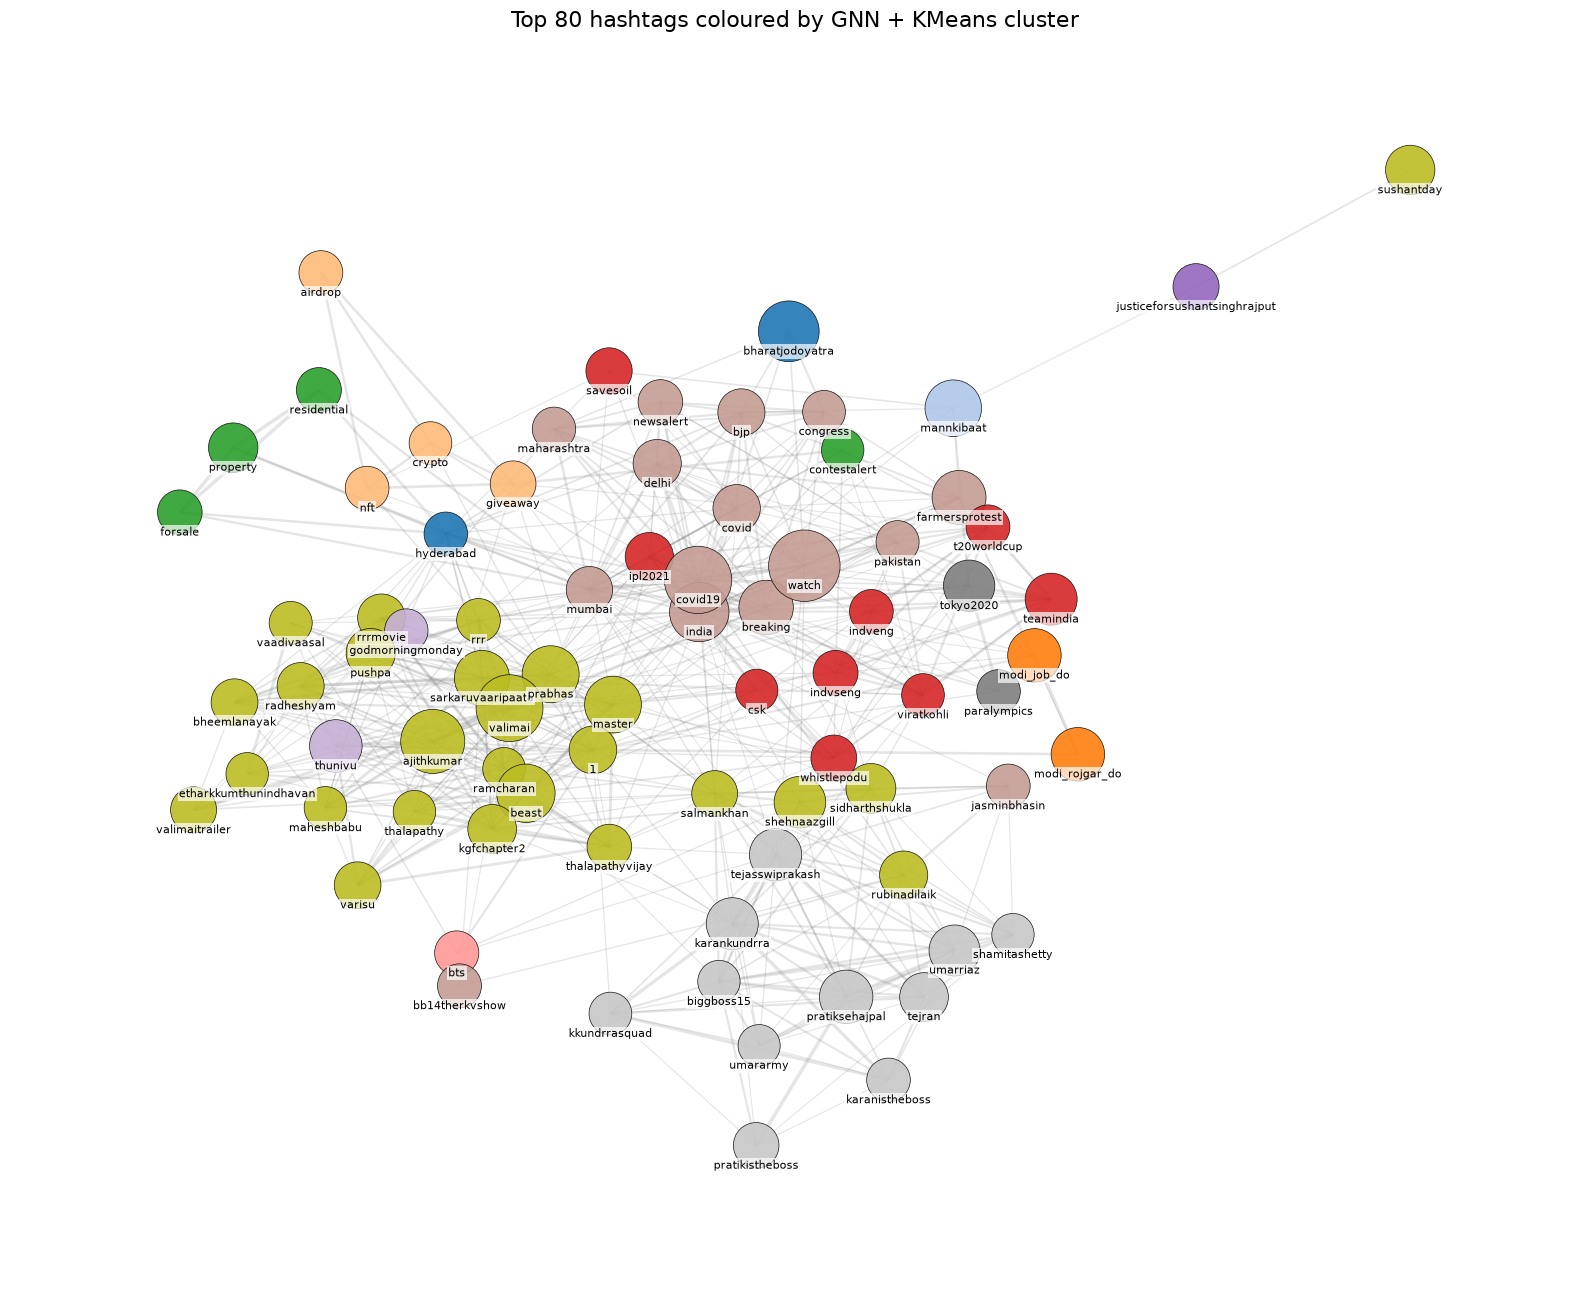

In [28]:
kmeans_label = {n: int(l) for n, l in zip(node_list, kmeans_labels)}
draw_hashtag_network(kmeans_label, 'Top 80 hashtags coloured by GNN + KMeans cluster', filename='hashtags_kmeans.svg')

## Export for Gephi and Neo4j

**Gephi**: we use `hashtags.gexf`.

In [29]:
for n in G.nodes():
    G.nodes[n]['count'] = int(tag_info.loc[n, 'count'])
    G.nodes[n]['louvain'] = int(louvain_label[n])
    G.nodes[n]['kmeans'] = int(kmeans_label[n])

nx.write_gexf(G, 'hashtags.gexf')
print('saved hashtags.gexf')

saved hashtags.gexf


**Neo4j**: (same as task1) export top 300 hashtags and the edges between them only for visibility.

In [30]:
NEO_TOP = 300
top_tags = tag_info.loc[node_list, 'count'].sort_values(ascending=False).head(NEO_TOP).index

neo_nodes = pd.DataFrame({
    'hashtag': top_tags,
    'count': tag_info.loc[top_tags, 'count'].values,
    'louvain': [louvain_label[n] for n in top_tags],
    'kmeans': [kmeans_label[n] for n in top_tags],
})
H = G.subgraph(top_tags)
neo_edges = pd.DataFrame([(a, b, d['weight']) for a, b, d in H.edges(data=True)],
                         columns=['source', 'target', 'weight'])

neo_nodes.to_csv('neo4j_hashtag_nodes.csv', index=False)
neo_edges.to_csv('neo4j_hashtag_edges.csv', index=False)
print(len(neo_nodes), 'nodes and', len(neo_edges), 'edges exported')

300 nodes and 3765 edges exported
